# Import

In [1]:
%reset -f
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import meshio
import sys
sys.path.append('../')

from sources.parameters import *
from sources.data import *
from sources.model import *
from sources.solver import *

# exact solution

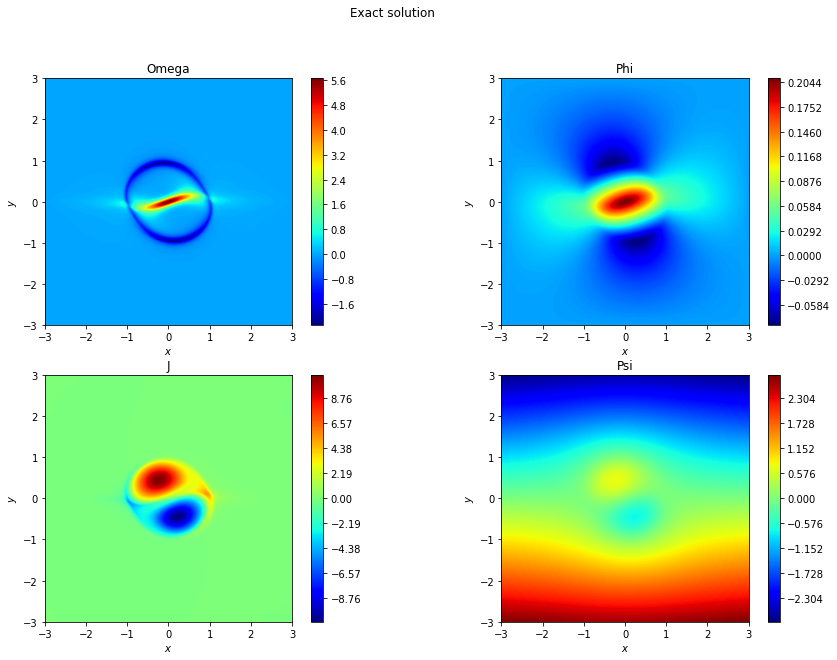

In [2]:
t=700 #600,741,830

# load exact solution
reader = meshio.read(DATA_PATH+'tiltC'+str(t)+'.vtk')
x = reader.points
triangles =  reader.cells_dict['triangle']
J = reader.point_data['current']
reader = meshio.read(DATA_PATH+'tiltO'+str(t)+'.vtk')
omega = reader.point_data['vorticity']
reader = meshio.read(DATA_PATH+'tiltphi'+str(t)+'.vtk')
phi = reader.point_data['stream']
reader = meshio.read(DATA_PATH+'tiltpsi'+str(t)+'.vtk')
psi = reader.point_data['champ']

# plot
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(15,10))
axs = axs.flatten()

# plot omega
axs[0].set_xlabel('$x$')
axs[0].set_ylabel('$y$')
axs[0].set_aspect('equal')
img0 = axs[0].tricontourf(x[:,0], x[:,1], triangles, omega, 800, cmap='jet');
cbar0 = plt.colorbar(img0, ax=axs[0])
axs[0].set_title('Omega')

# plot phi
axs[1].set_xlabel('$x$')
axs[1].set_ylabel('$y$')
axs[1].set_aspect('equal')
img1 = axs[1].tricontourf(x[:,0], x[:,1], triangles, phi, 800, cmap='jet');
cbar1 = plt.colorbar(img1, ax=axs[1])
axs[1].set_title('Phi')

# plot J
axs[2].set_xlabel('$x$')
axs[2].set_ylabel('$y$')
axs[2].set_aspect('equal')
img2 = axs[2].tricontourf(x[:,0], x[:,1], triangles, J, 800, cmap='jet');
cbar2 = plt.colorbar(img2, ax=axs[2])
axs[2].set_title('J')

# plot psi
axs[3].set_xlabel('$x$')
axs[3].set_ylabel('$y$')
axs[3].set_aspect('equal')
img3 = axs[3].tricontourf(x[:,0], x[:,1], triangles, psi, 800, cmap='jet');
cbar3 = plt.colorbar(img3, ax=axs[3])
axs[3].set_title('Psi')

#fig.tight_layout()
plt.suptitle('Exact solution');

# make data

In [3]:
X_r, X_data, u_data = gen_train_data(1_000_000,5_000,5_000)

In [4]:
X_r

<tf.Tensor: shape=(1000000, 3), dtype=float32, numpy=
array([[ 1.4598757 ,  0.33248448, -1.8287172 ],
       [ 1.0328323 , -1.6722422 ,  1.4410391 ],
       [ 2.6769538 ,  2.1895494 , -0.07318926],
       ...,
       [ 1.1311644 , -0.5702462 ,  2.5379324 ],
       [ 1.4640796 , -0.4736209 , -0.9082525 ],
       [ 3.9623666 , -0.13518047,  2.2840357 ]], dtype=float32)>

In [5]:
X_data = tf.concat([tf.zeros((len(x),1), dtype=DTYPE), x[:,0:1], x[:,1:2]], axis=1)
X_data

<tf.Tensor: shape=(5706, 3), dtype=float32, numpy=
array([[ 0.        , -3.        ,  3.        ],
       [ 0.        , -2.8       ,  3.        ],
       [ 0.        , -2.8774338 ,  2.868292  ],
       ...,
       [ 0.        ,  0.3861511 , -0.05844375],
       [ 0.        ,  0.35041127, -0.08620989],
       [ 0.        ,  0.3838803 , -0.08545815]], dtype=float32)>

In [6]:
u_data = np.vstack((omega, phi, J, psi)).T
u_data = tf.cast(u_data, DTYPE)
u_data

<tf.Tensor: shape=(5706, 4), dtype=float32, numpy=
array([[-3.1595611e-36, -6.7837279e-38,  6.2813585e-36, -2.8333333e+00],
       [-2.1052195e-36, -7.4541236e-35,  1.1773421e-35, -2.8218527e+00],
       [ 1.5237091e-05, -8.9286550e-05,  2.5508178e-05, -2.6944208e+00],
       ...,
       [ 5.0300533e-01,  1.4521615e-01, -4.7473588e+00, -3.3966118e-01],
       [ 3.3166862e-01,  1.4366658e-01, -5.4072385e+00, -3.8454068e-01],
       [ 3.1978685e-01,  1.3816142e-01, -5.4416585e+00, -3.8674164e-01]],
      dtype=float32)>

# training

In [17]:
from time import time

model_omega = PhysicsInformedNN(lb, ub, output_dim=1, num_hidden_layers=4, num_neurons_per_layer=30, activation='tanh')
model_phi = PhysicsInformedNN(lb, ub, output_dim=1, num_hidden_layers=4, num_neurons_per_layer=30, activation='tanh')
model_J = PhysicsInformedNN(lb, ub, output_dim=1, num_hidden_layers=4, num_neurons_per_layer=30, activation='tanh')
model_psi = PhysicsInformedNN(lb, ub, output_dim=1, num_hidden_layers=4, num_neurons_per_layer=30, activation='tanh')

solver = multiPINNSolver(model_omega, model_phi, model_J, model_psi, batch_size = 1_000)

lr_omega = tf.keras.optimizers.schedules.ExponentialDecay(
    1e-2,
    decay_steps=100,
    decay_rate=0.98,
    staircase=True)

lr_phi = tf.keras.optimizers.schedules.ExponentialDecay(
    1e-2,
    decay_steps=100,
    decay_rate=0.98,
    staircase=True)

lr_J = tf.keras.optimizers.schedules.ExponentialDecay(
    1e-2,
    decay_steps=100,
    decay_rate=0.98,
    staircase=True)

lr_psi = tf.keras.optimizers.schedules.ExponentialDecay(
    1e-2,
    decay_steps=100,
    decay_rate=0.98,
    staircase=True)

optim_omega = tf.keras.optimizers.Adam(learning_rate=lr_omega)
optim_phi = tf.keras.optimizers.Adam(learning_rate=lr_phi)    
optim_J = tf.keras.optimizers.Adam(learning_rate=lr_J)    
optim_psi = tf.keras.optimizers.Adam(learning_rate=lr_psi)

t0 = time()
try: 
  solver.solve(optim_omega, optim_phi, optim_J, optim_psi, X_r, X_data, u_data)
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))
alert('MHD')

Epoch 02_300: 

                    loss_omega   5.1079e+02  
                    loss_phi     2.7401e+01
                    loss_J       4.0237e+03
                    loss_psi     4.0550e+02
                    total_loss   4.9674e+03

Training time: 776.4082567691803 seconds


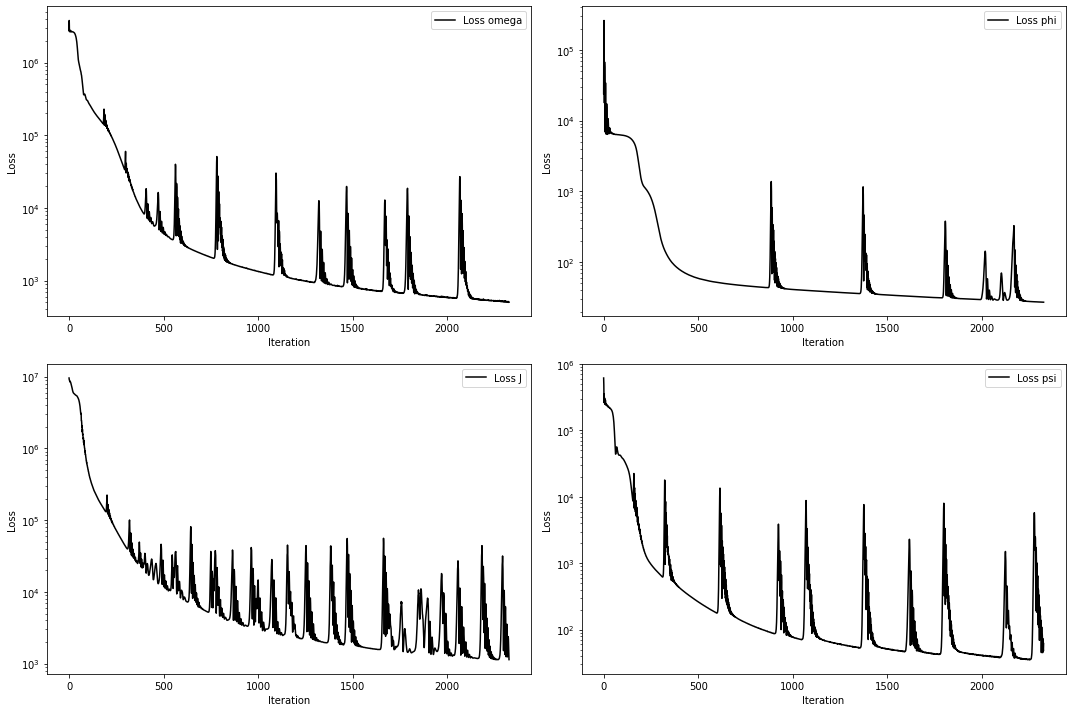

In [18]:
solver.plot_losses_history()

# Check results

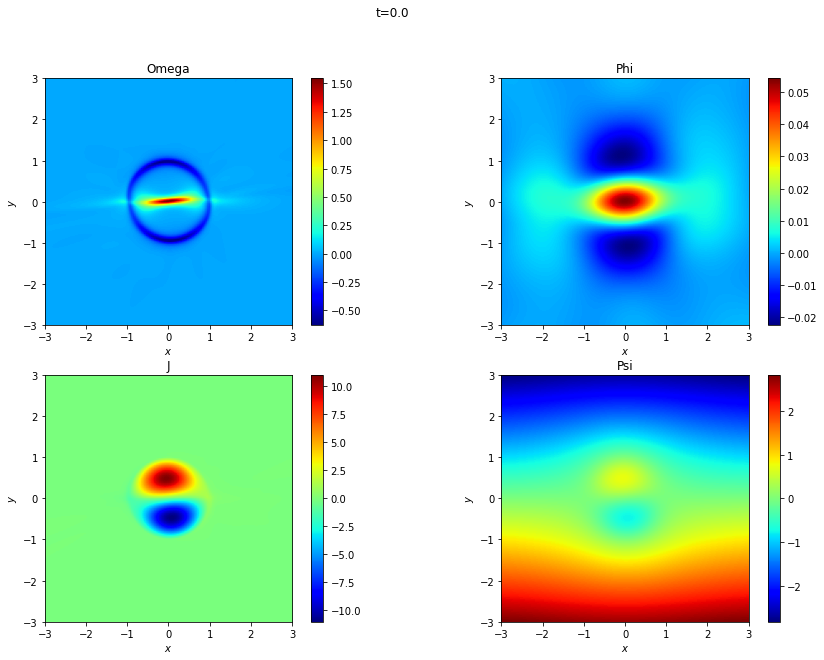

In [9]:
N = 150
t = 0.

# compute solution using PINN
xspace = np.linspace(-3,3,N)
yspace = np.linspace(-3,3,N)
tfinal = t * np.ones(N*N)

X, Y = np.meshgrid(xspace, yspace)
Xgrid = np.vstack([tfinal.flatten(), X.flatten(), Y.flatten()]).T

omega = model_omega(tf.cast(Xgrid,DTYPE))
phi = model_phi(tf.cast(Xgrid,DTYPE))
J = model_J(tf.cast(Xgrid,DTYPE))
psi = model_psi(tf.cast(Xgrid,DTYPE))

# reshape for plotting
omega = omega.numpy().reshape(N,N)
phi = phi.numpy().reshape(N,N)
J = J.numpy().reshape(N,N)
psi = psi.numpy().reshape(N,N)

# affichage
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(15,10))
axs = axs.flatten()

# plot omega
axs[0].set_xlabel('$x$')
axs[0].set_ylabel('$y$')
axs[0].set_aspect('equal')
img0 = axs[0].imshow(omega, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar0 = plt.colorbar(img0, ax=axs[0])
axs[0].set_title('Omega')

# plot phi
axs[1].set_xlabel('$x$')
axs[1].set_ylabel('$y$')
axs[1].set_aspect('equal')
img1 = axs[1].imshow(phi, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar1 = plt.colorbar(img1, ax=axs[1])
axs[1].set_title('Phi')

# plot J
axs[2].set_xlabel('$x$')
axs[2].set_ylabel('$y$')
axs[2].set_aspect('equal')
img2 = axs[2].imshow(J, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar2 = plt.colorbar(img2, ax=axs[2])
axs[2].set_title('J')

# plot psi
axs[3].set_xlabel('$x$')
axs[3].set_ylabel('$y$')
axs[3].set_aspect('equal')
img3 = axs[3].imshow(psi, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar3 = plt.colorbar(img3, ax=axs[3])
axs[3].set_title('Psi')

#fig.tight_layout()
plt.suptitle('t={}'.format(t))
plt.show()

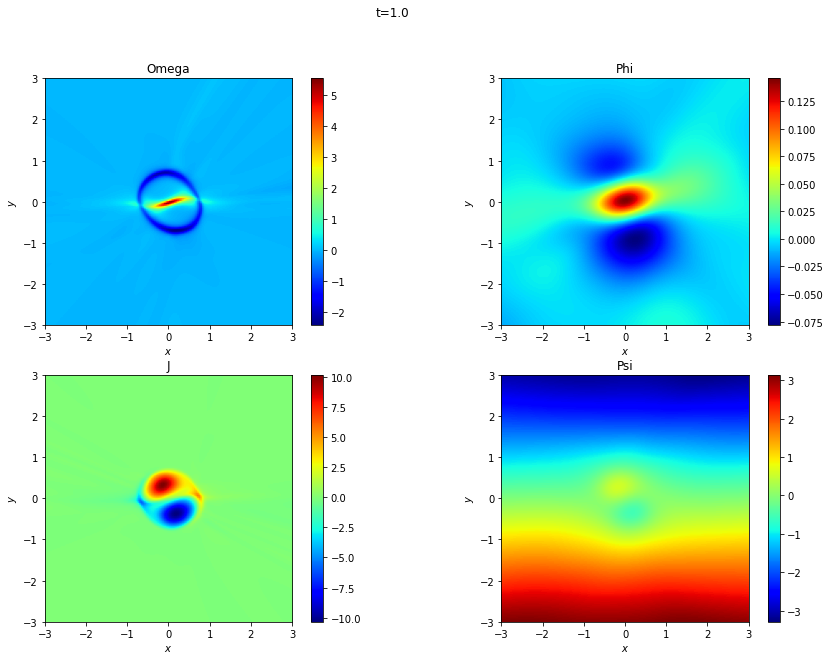

In [21]:
N = 150
t = 1.

# compute solution using PINN
xspace = np.linspace(-3,3,N)
yspace = np.linspace(-3,3,N)
tfinal = t * np.ones(N*N)

X, Y = np.meshgrid(xspace, yspace)
Xgrid = np.vstack([tfinal.flatten(), X.flatten(), Y.flatten()]).T

omega = model_omega(tf.cast(Xgrid,DTYPE))
phi = model_phi(tf.cast(Xgrid,DTYPE))
J = model_J(tf.cast(Xgrid,DTYPE))
psi = model_psi(tf.cast(Xgrid,DTYPE))

# reshape for plotting
omega = omega.numpy().reshape(N,N)
phi = phi.numpy().reshape(N,N)
J = J.numpy().reshape(N,N)
psi = psi.numpy().reshape(N,N)

# affichage
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(15,10))
axs = axs.flatten()

# plot omega
axs[0].set_xlabel('$x$')
axs[0].set_ylabel('$y$')
axs[0].set_aspect('equal')
img0 = axs[0].imshow(omega, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar0 = plt.colorbar(img0, ax=axs[0])
axs[0].set_title('Omega')

# plot phi
axs[1].set_xlabel('$x$')
axs[1].set_ylabel('$y$')
axs[1].set_aspect('equal')
img1 = axs[1].imshow(phi, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar1 = plt.colorbar(img1, ax=axs[1])
axs[1].set_title('Phi')

# plot J
axs[2].set_xlabel('$x$')
axs[2].set_ylabel('$y$')
axs[2].set_aspect('equal')
img2 = axs[2].imshow(J, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar2 = plt.colorbar(img2, ax=axs[2])
axs[2].set_title('J')

# plot psi
axs[3].set_xlabel('$x$')
axs[3].set_ylabel('$y$')
axs[3].set_aspect('equal')
img3 = axs[3].imshow(psi, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar3 = plt.colorbar(img3, ax=axs[3])
axs[3].set_title('Psi')

#fig.tight_layout()
plt.suptitle('t={}'.format(t))
plt.show()